In [1]:
import pandas as pd
import numpy as np
from astropy.io import fits
import matplotlib.pyplot as plt

fits_file = 'chandra_COSMOS_legacy_opt_NIR_counterparts_20160113_4d.fits'
hdul = fits.open(fits_file)
df = pd.DataFrame(hdul[1].data)

df.replace(-99.000, np.nan, inplace=True)
df.replace(-99, np.nan, inplace=True)

# Filter for valid spectroscopic redshifts (z_spec)
mask_valid_z = (df['z_spec'].notna()) # & (df['z_spec'] > 0) # Add (df['Qg'] >= 1.5))
df_z = df[mask_valid_z].copy()

print(f"Total sources with valid z_spec: {len(df_z)}")

# Show all columns
pd.set_option('display.max_columns', None)
df.head(3)

Total sources with valid z_spec: 2287


,id_x,RA_x,DEC_x,DET_ML_F,DET_ML_S,DET_ML_H,flux_F,flux_S,flux_H,HR,HR_lo_lim,HR_up_lim,id_i,ra_i,dec_i,i_mag,i_mag_err,flag_i_mag,id_k_uv,ra_k_uv,dec_k_uv,k_uv_mag,k_uv_mag_err,id_k_cfht,ra_k_cfht,dec_k_cfht,k_cfht_mag,k_cfht_mag_err,ra_irac,dec_irac,irac_mag,irac_mag_err,ra_splash,dec_splash,splash_mag,splash_mag_err,final_id_flag,star_flag,z_best,z_spec,Instr,Qg,spec_type,z_phot,phot_type,id_xmm,dist_lum,Lx_0510,Lx_052,Lx_210,NH,abs_corr_0510,abs_corr_052,abs_corr_210,NH_lo,abs_corr_0510_lo,abs_corr_052_lo,abs_corr_210_lo,NH_up,abs_corr_0510_up,abs_corr_052_up,abs_corr_210_up
0,cid_1,149.63956,1.991034,10.910000,NaN,NaN,1.180000e-15,-3.940000e-16,-1.120000e-14,NaN,0.52,NaN,860777.0,149.639496,1.991038,26.059999,0.22,1.0,455942.0,149.639513,1.991030,22.110001,0.03,860777.0,149.639481,1.991048,22.180000,0.05,149.639435,1.991108,21.639999,0.01,149.639513,1.991030,21.420000,0.01,1.0,0,1.928,NaN,None,0.0,-9.0,1.928,3.0,NaN,15123.339844,43.229000,-42.752998,-44.206001,NaN,NaN,NaN,NaN,39.200001,0.531,0.081,0.796,NaN,NaN,NaN,NaN
1,cid_100,150.34101,2.367167,353.079987,284.350006,82.540001,1.430000e-14,3.670000e-15,9.880000e-15,-0.27,-0.39,-0.13,1210176.0,150.341034,2.367181,23.620001,0.03,1.0,704286.0,150.341070,2.367165,21.270000,0.01,1210176.0,150.341049,2.367159,21.309999,0.03,150.341049,2.367121,20.850000,0.01,150.341070,2.367165,20.590000,0.01,1.0,0,1.590,1.59,VIMOS,1.5,1.0,1.572,1.0,320.0,11920.509766,44.138000,43.547001,43.977001,0.0,1.0,1.0,1.0,0.000000,1.000,1.000,1.000,4.46,0.769,0.438,0.964
2,cid_1000,149.67574,2.010529,124.730003,141.699997,NaN,6.850000e-15,2.050000e-15,-1.320000e-14,NaN,NaN,-0.91,857679.0,149.675766,2.010352,24.190001,0.05,1.0,470092.0,149.675807,2.010416,21.240000,0.01,857679.0,149.675812,2.010447,21.540001,0.03,149.675766,2.010402,20.830000,0.01,149.675807,2.010416,20.530001,0.01,1.0,0,1.847,NaN,None,0.0,-9.0,1.847,3.0,5355.0,14344.620117,43.953999,43.430000,-44.238998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,1.000,1.000,1.000


## Histogram of z_spec (all)

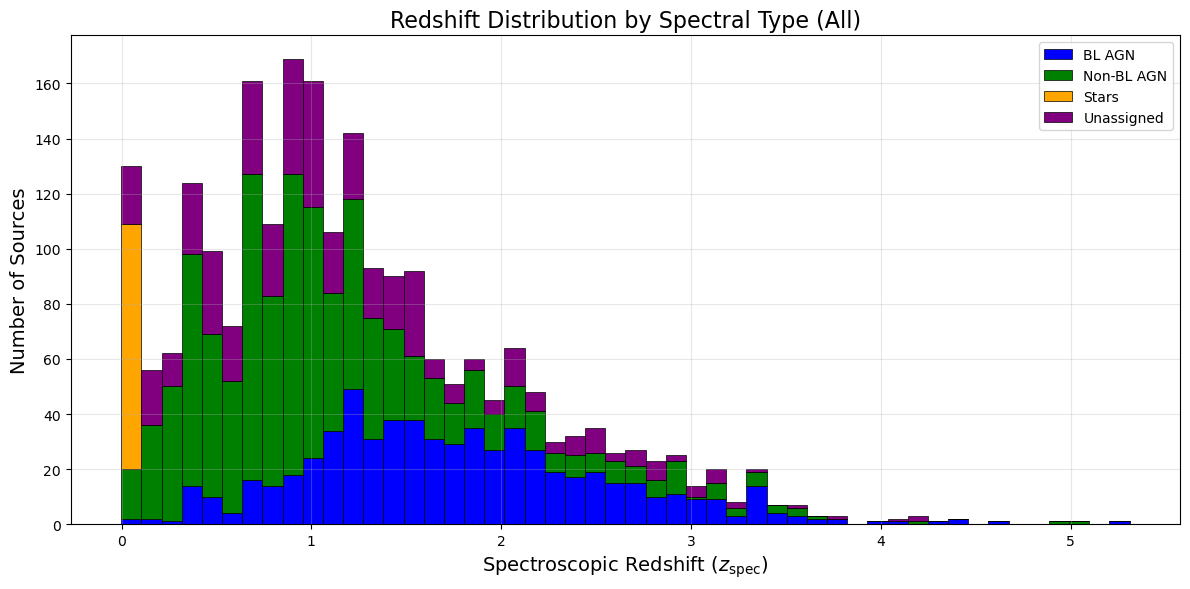

Min z_spec: -0.0010000000474974513
Max z_spec: 5.309999942779541


In [2]:
plt.figure(figsize=(12, 6))

# Define mask for each category
mask_bl = df_z['spec_type'] == 1
mask_non_bl = df_z['spec_type'] == 2
mask_star = df_z['spec_type'] == 0
mask_unassigned = ~(df_z['spec_type'].isin([0, 1, 2]))

# Plot each category with transparency to see overlaps
bins = 50

plt.hist([df_z.loc[mask_bl, 'z_spec'].dropna(), 
          df_z.loc[mask_non_bl, 'z_spec'].dropna(), 
          df_z.loc[mask_star, 'z_spec'].dropna(), 
          df_z.loc[mask_unassigned, 'z_spec'].dropna()], 
         bins=bins, 
         stacked=True, 
         color=['blue', 'green', 'orange', 'purple'], 
         edgecolor='black', 
         linewidth=0.5, 
         label=['BL AGN', 'Non-BL AGN', 'Stars', 'Unassigned'])

# Formatting
plt.xlabel('Spectroscopic Redshift ($z_{\\rm spec}$)', fontsize=14)
plt.ylabel('Number of Sources', fontsize=14)
plt.title('Redshift Distribution by Spectral Type (All)', fontsize=16)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Min z_spec: {df_z['z_spec'].min()}")
print(f"Max z_spec: {df_z['z_spec'].max()}")

## Two Selection Criteria

In [3]:
pre_df = df_z

pre_df['flux_S'] = pd.to_numeric(pre_df['flux_S'], errors='coerce')
pre_df['i_mag'] = pd.to_numeric(pre_df['i_mag'], errors='coerce')

mask_valid = (pre_df['flux_S'] > 0) & (pre_df['i_mag'] > 0)
pre_df = pre_df[mask_valid].copy()

print(f"Sources with valid flux_S and i_mag: {len(pre_df)}")

pre_df['X_over_O'] = np.log10(pre_df['flux_S']) + (pre_df['i_mag'] / 2.5) + 5.352

# Two AGN criteria
# Criterion 1: L_0.5-10 keV > 3e42 erg/s (log10 > 42.5)
mask_luminosity = pre_df['Lx_0510'] > 42.5   # Where 42.5 = np.log10(3) + 42

# Criterion 2: -1 <= X/O <= 1
mask_xo = (pre_df['X_over_O'] >= -1.0) & (pre_df['X_over_O'] <= 1.0)

# Combine with OR
agn_mask = mask_luminosity | mask_xo

f1_sources = pre_df[agn_mask].copy()

print(f"Sources passing at least one criterion: {len(f1_sources)}")
print(f"Sources rejected: {len(pre_df) - len(f1_sources)}")

Sources with valid flux_S and i_mag: 1862
Sources passing at least one criterion: 1597
Sources rejected: 265


### Figure 1

#### Color-Coding The data

In [4]:
def get_spec_type_label(spec_type):
    if spec_type == 0:
        return 'Star'
    elif spec_type == 1:
        return 'BL AGN'
    elif spec_type == 2:
        return 'Non-BL AGN'
    else:
        return 'Unassigned'

pre_df['spec_type_label'] = pre_df['spec_type'].apply(get_spec_type_label)

spec_colors = {
    'Star': 'orange',
    'BL AGN': 'blue',
    'Non-BL AGN': 'green',
    'Unassigned': 'gray'
}

spec_markers = {
    'Star': 's',
    'BL AGN': 'o',
    'Non-BL AGN': 'o',
    'Unassigned': 'o'
}

spec_labels = {
    'Star': 'Star',
    'BL AGN': 'BL AGN',
    'Non-BL AGN': 'Non-BL AGN',
    'Unassigned': 'Unassigned'
}

#### De Graph

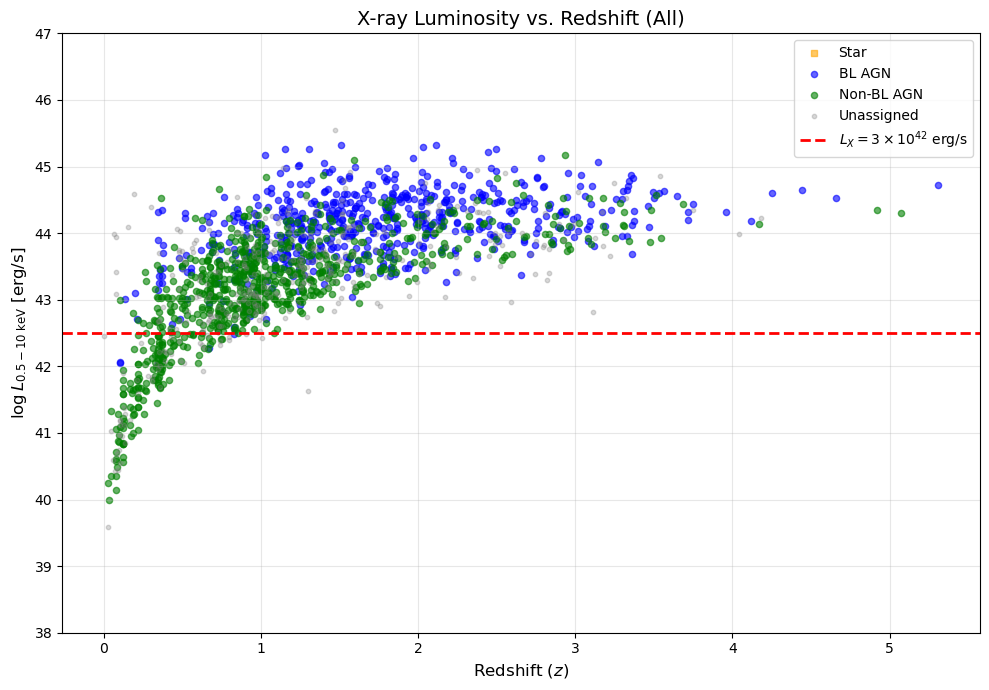

In [5]:
fig, ax = plt.subplots(figsize=(10, 7))

# Filter out extreme Lx values for plotting
plot_df = pre_df[pre_df['Lx_0510'] > 0].copy()

for stype in ['Star', 'BL AGN', 'Non-BL AGN', 'Unassigned']:
    subset = plot_df[plot_df['spec_type_label'] == stype]
    ax.scatter(
        subset['z_spec'],
        subset['Lx_0510'],
        s=20 if stype != 'Unassigned' else 10,
        alpha=0.6 if stype != 'Unassigned' else 0.3,
        color=spec_colors[stype],
        marker=spec_markers[stype],
        label=spec_labels[stype]
    )

# Add the luminosity threshold line
ax.axhline(y=42.5, color='red', linestyle='--', linewidth=2, label=r'$L_X = 3 \times 10^{42}$ erg/s')

# Labels and formatting
ax.set_xlabel('Redshift ($z$)', fontsize=12)
ax.set_ylabel(r'$\log L_{0.5-10\ \mathrm{keV}}$ [erg/s]', fontsize=12)
ax.set_title('X-ray Luminosity vs. Redshift (All)', fontsize=14)
ax.legend(loc='upper right', fontsize=10)
ax.grid(True, alpha=0.3)
ax.set_ylim(38, 47)

plt.tight_layout()
plt.show()

### Figure 2

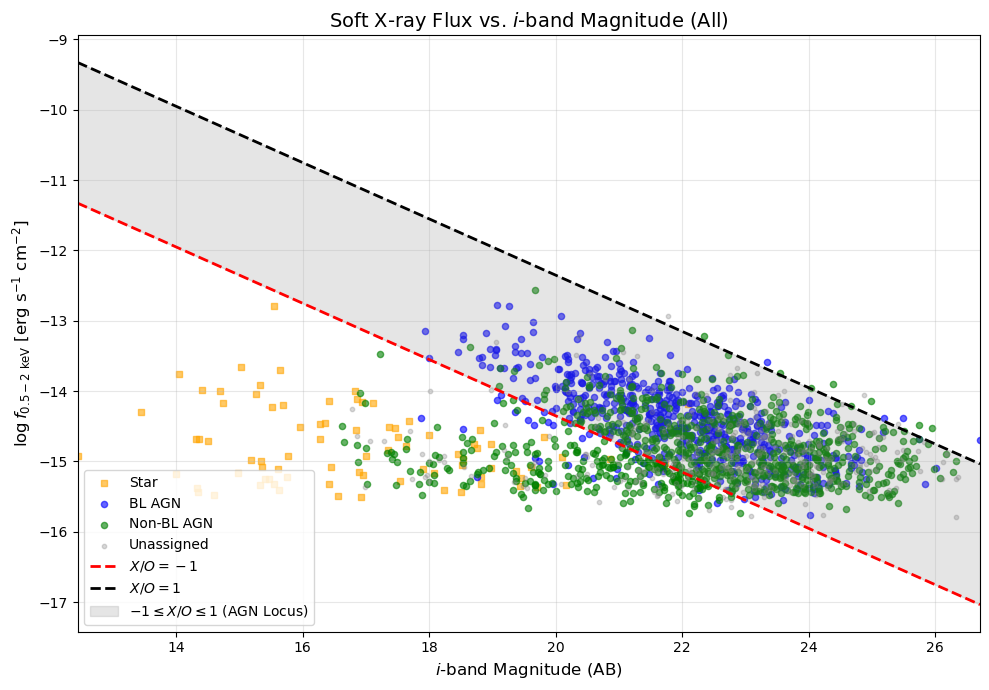

In [6]:
fig2, ax2 = plt.subplots(figsize=(10, 7))

# Filter out invalid magnitudes and fluxes
plot_df2 = pre_df[(pre_df['i_mag'] > 0) & (pre_df['flux_S'] > 0)].copy()

for stype in ['Star', 'BL AGN', 'Non-BL AGN', 'Unassigned']:
    subset = pre_df[pre_df['spec_type_label'] == stype]
    ax2.scatter(
        subset['i_mag'],
        np.log10(subset['flux_S']),
        s=20 if stype != 'Unassigned' else 10,
        alpha=0.6 if stype != 'Unassigned' else 0.3,
        color=spec_colors[stype],
        marker=spec_markers[stype],
        label=spec_labels[stype]
    )

# --- Add the AGN locus lines ---
# X/O = -1 and X/O = 1 lines
i_mag_range = np.linspace(plot_df2['i_mag'].min(), plot_df2['i_mag'].max(), 100)

# X/O = -1: log10(flux_S) = -1 - i_mag/2.5 - 5.352
log_fx_minus1 = -1 - i_mag_range / 2.5 - 5.352
ax2.plot(i_mag_range, log_fx_minus1, color='red', linestyle='--', linewidth=2, label=r'$X/O = -1$')

# X/O = 1: log10(flux_S) = 1 - i_mag/2.5 - 5.352
log_fx_plus1 = 1 - i_mag_range / 2.5 - 5.352
ax2.plot(i_mag_range, log_fx_plus1, color='black', linestyle='--', linewidth=2, label=r'$X/O = 1$')

# Shade the AGN locus region (-1 <= X/O <= 1)
ax2.fill_between(
    i_mag_range,
    log_fx_minus1,
    log_fx_plus1,
    color='gray',
    alpha=0.2,
    label=r'$-1 \leq X/O \leq 1$ (AGN Locus)'
)

# --- Labels and formatting ---
ax2.set_xlabel('$i$-band Magnitude (AB)', fontsize=12)
ax2.set_ylabel(r'$\log f_{0.5-2\ \mathrm{keV}}$ [erg s$^{-1}$ cm$^{-2}$]', fontsize=12)
ax2.set_title('Soft X-ray Flux vs. $i$-band Magnitude (All)', fontsize=14)
ax2.legend(loc='lower left', fontsize=10)
ax2.grid(True, alpha=0.3)

# Set x-axis limits (bright to faint)
ax2.set_xlim(plot_df2['i_mag'].min(), plot_df2['i_mag'].max())

plt.tight_layout()
plt.show()

### Summary

In [7]:
# --- Ensure spec_type_label exists in both DataFrames ---
if 'spec_type_label' not in pre_df.columns:
    pre_df['spec_type_label'] = pre_df['spec_type'].apply(get_spec_type_label)

if 'spec_type_label' not in f1_sources.columns:
    f1_sources['spec_type_label'] = f1_sources['spec_type'].apply(get_spec_type_label)

# --- Define masks on the full pre-selected sample (pre_df) ---
mask_lum_pre = pre_df['Lx_0510'] > 42.5
mask_xo_pre = (pre_df['X_over_O'] >= -1.0) & (pre_df['X_over_O'] <= 1.0)

# --- Function to count criteria for a given label ---
def count_criteria(label):
    # Subset from pre_df (full sample)
    subset = pre_df[pre_df['spec_type_label'] == label]
    if len(subset) == 0:
        return {'Only Luminosity': 0, 'Only X/O': 0, 'Both': 0, 'Rejected': 0, 'Total': 0}
    
    # Masks for this subset
    lum = mask_lum_pre.loc[subset.index]
    xo = mask_xo_pre.loc[subset.index]
    
    only_lum = (lum & ~xo).sum()
    only_xo = (~lum & xo).sum()
    both = (lum & xo).sum()
    total = len(subset)
    
    # Rejected = total - (only_lum + only_xo + both)
    rejected = total - (only_lum + only_xo + both)
    
    return {'Total': total, 'Only Luminosity': only_lum, 'Only X/O': only_xo, 'Both': both, 
            'Rejected': rejected}

# --- Define the labels of interest ---
labels = ['BL AGN', 'Non-BL AGN', 'Star', 'Unassigned']
results = {label: count_criteria(label) for label in labels}

# --- Create a pandas DataFrame ---
df_counts = pd.DataFrame(results).T

# Add a row for "All" (sum of all categories)
all_counts = df_counts.sum()
df_counts.loc['All'] = all_counts

print(df_counts)

            Total  Only Luminosity  Only X/O  Both  Rejected
BL AGN        596               32         2   558         4
Non-BL AGN    822              101        21   567       133
Star           85                0         4     0        81
Unassigned    359               38        13   261        47
All          1862              171        40  1386       265
